# SHEVDC 车辆运行数据分析

> **一句话结论**：这辆电动车在 35 小时的记录里行驶 **214 km**、耗电 **45.96 kWh**（约 **21.5 kWh/100km**），并完成 **2 次交流慢充**（共充入 37.58 kWh，平均功率 3.25 kW）。电池一致性良好——单体电压极差中位数仅 9 mV、最大 96 mV；温度控制在 5–13 °C、最大温差 2 °C。

数据来源：SHEVDC 平台导出的单车 10 秒级行驶/充电记录（2019-01-10 01:12 至 2019-01-11 12:16，6,231 条）。

本 notebook 依次回答四个问题：

| # | 问题 | 方法 |
|---|------|------|
| Q1 | 数据质量如何？能直接用来分析吗？ | 采样间隔、覆盖率、缺口统计 |
| Q2 | 这段时间车辆在干什么？ | 车辆状态 × 充电状态交叉分析、速度分布 |
| Q3 | 充电行为是什么样？ | 识别充电会话、充电功率与 SOC 曲线 |
| Q4 | 电池健康与能耗如何？ | 单体电压极差、温度、充放电能量积分 |

## 0. 字段说明（GB/T 32960 车辆数据格式）

| 字段 | 含义 |
|---|---|
| `vehiclestatus` | 车辆状态：1=启动，2=熄火 |
| `chargestatus` | 充电状态：1=停车充电，2=行驶充电（能量回收），3=未充电，4=充电完成 |
| `speed` | 车速（km/h） |
| `sumvoltage` / `sumcurrent` | 总电压（V）/ 总电流（A，正=放电，负=充电） |
| `soc` | 剩余电量（%） |
| `max/min_cell_volt` | 最高/最低单体电压（V） |
| `max/min_temp` | 最高/最低温度（°C） |
| `insulationresistance` | 绝缘电阻上报值 |
| `summileage` | 累计里程（km） |

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

candidates = [Path("data/raw/SHEVDC_OV6N7709.csv"), Path("../data/raw/SHEVDC_OV6N7709.csv")]
DATA = next(p for p in candidates if p.exists())
OUT = Path("images") if Path("images").exists() else Path("../images")

df = pd.read_csv(DATA, dtype={"summileage": str})
df["time"] = pd.to_datetime(df["time"])
df["mileage"] = pd.to_numeric(df["summileage"].str.replace(",", ""), errors="coerce")
df["dt"] = df["time"].diff().dt.total_seconds()
df["power_kw"] = df["sumvoltage"] * df["sumcurrent"] / 1000
df["volt_spread"] = df["max_cell_volt"] - df["min_cell_volt"]
df["temp_spread"] = df["max_temp"] - df["min_temp"]
df["energy_kwh"] = df["power_kw"] * df["dt"] / 3600  # 正=放电，负=充电

print("数据形状:", df.shape)
print("时间范围:", df.time.min(), "→", df.time.max())
df.head(3)

数据形状: (6231, 30)
时间范围: 2019-01-10 01:12:00 → 2019-01-11 12:16:18


,time,vehiclestatus,chargestatus,runmodel,speed,summileage,sumvoltage,sumcurrent,soc,dcdcstatus,...,max_temp,min_temp_num,min_temp_probe_id,min_temp,mileage,dt,power_kw,volt_spread,temp_spread,energy_kwh
0,2019-01-10 01:12:00,1,4,1,0.0,39938.0,397.5,0.4,100,1,...,6,1,24,5,39938.0,NaN,0.159,0.01,1,NaN
1,2019-01-10 01:12:10,1,4,1,0.0,39938.0,397.5,0.4,100,1,...,6,1,24,5,39938.0,10.0,0.159,0.01,1,0.000442
2,2019-01-10 01:12:20,1,4,1,0.0,39938.0,397.5,0.4,100,1,...,6,1,24,5,39938.0,10.0,0.159,0.01,1,0.000442


## 1. 数据质量：只有一半时间是"在线"的

车载终端不是一直在传数据，而是**车辆上电 / 充电时才上传**。所以先算清楚覆盖率和缺口，否则后面所有"时长""能耗"的结论都会错。

In [2]:
span = (df.time.max() - df.time.min()).total_seconds()
expected = int(span / 10) + 1
print("时间跨度: %.1f 小时" % (span / 3600))
print("按 10 秒采样应有: %d 条，实际: %d 条，覆盖率: %.1f%%" % (expected, len(df), len(df) / expected * 100))
print("\n采样间隔分布（前 6 种）:")
print(df.dt.value_counts().head(6).to_string())
print("\n>60 秒的缺口: %d 段，最长缺口 %.0f 分钟（%.1f 小时）" % (
    (df.dt > 60).sum(), df.dt.max() / 60, df.dt.max() / 3600))
print("\n每天有数据的小时（行数）:")
print(df.groupby(df.time.dt.hour).size().to_string())

时间跨度: 35.1 小时
按 10 秒采样应有: 12626 条，实际: 6231 条，覆盖率: 49.4%

采样间隔分布（前 6 种）:
dt
10.0     5936
40.0      184
70.0       57
100.0      15
130.0       6
107.0       3

>60 秒的缺口: 106 段，最长缺口 811 分钟（13.5 小时）

每天有数据的小时（行数）:
time
1     279
2     222
3     356
4     360
5     345
6     341
7     351
8     381
9     492
10    454
11    572
12    395
13    300
14    347
15    319
16    309
17    228
18    180


**结论**：35.1 小时里只有 **49.3%** 的时刻在上报，共 **106 段**超过 60 秒的缺口，最长一段 13.5 小时。这说明数据只覆盖"用车 + 充电"时段，**不能当成 24 小时连续监测**；做能耗积分时必须先过滤掉跨缺口的段落（后面会用 `dt ≤ 30s` 过滤）。

## 2. 工况画像：这辆车的时间花在哪

把"车辆状态"和"充电状态"交叉，就能还原出四个典型工况：停车充电、行驶、行驶中能量回收、充电完成。

In [3]:
status = pd.crosstab(df.vehiclestatus, df.chargestatus, margins=True)
status.index = ["启动" if i == 1 else ("熄火" if i == 2 else i) for i in status.index]
status.columns = ["停车充电" if c == 1 else ("行驶充电" if c == 2 else ("未充电" if c == 3 else ("充电完成" if c == 4 else c))) for c in status.columns]
display(status)

profile = df.groupby(["vehiclestatus", "chargestatus"]).agg(
    记录数=("time", "size"),
    时长小时=("dt", lambda s: s.clip(upper=10).sum() / 3600),
    平均速度=("speed", "mean"),
    平均电流=("sumcurrent", "mean"),
    平均SOC=("soc", "mean"),
).round(2)
print(profile.to_string())

moving = df[df.speed > 0]
print("\n行驶记录 %d 条（约 %.2f 小时），行驶中平均速度 %.1f km/h，最高 %.1f km/h" % (
    len(moving), len(moving) * 10 / 3600, moving.speed.mean(), df.speed.max()))
print("速度分位数: p50=%.1f, p90=%.1f, p95=%.1f" % tuple(df.speed.quantile([.5, .9, .95])))

,停车充电,行驶充电,未充电,充电完成,All
启动,0,272,1539,54,1865
熄火,4366,0,0,0,4366
All,4366,272,1539,54,6231


                             记录数   时长小时   平均速度   平均电流   平均SOC
vehiclestatus chargestatus                                   
1             2              272   0.76  46.67 -22.09   58.80
              3             1539   4.28  32.71  32.92   63.59
              4               54   0.15   1.09   6.10  100.00
2             1             4366  12.13   0.00  -8.96   55.97

行驶记录 1406 条（约 3.91 小时），行驶中平均速度 44.9 km/h，最高 100.7 km/h
速度分位数: p50=0.0, p90=51.2, p95=64.4


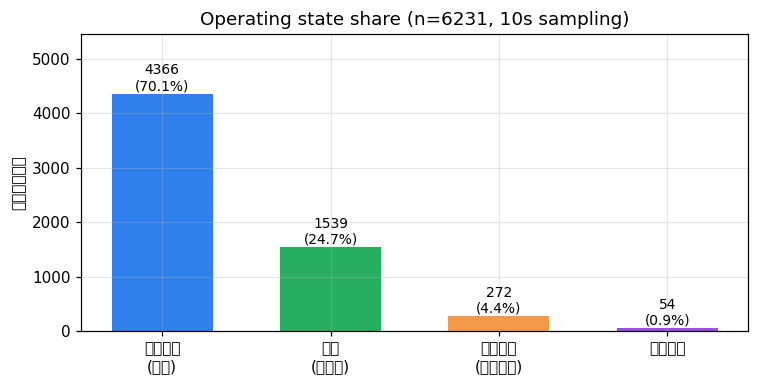

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
labels = ["停车充电\n(熄火)", "行驶\n(未充电)", "行驶充电\n(能量回收)", "充电完成"]
values = [
    len(df[(df.vehiclestatus == 2) & (df.chargestatus == 1)]),
    len(df[(df.vehiclestatus == 1) & (df.chargestatus == 3)]),
    len(df[(df.vehiclestatus == 1) & (df.chargestatus == 2)]),
    len(df[(df.vehiclestatus == 1) & (df.chargestatus == 4)]),
]
colors = ["#2F80ED", "#27AE60", "#F2994A", "#9B51E0"]
bars = ax.bar(labels, values, color=colors, width=0.6)
for b, v in zip(bars, values):
    ax.text(b.get_x() + b.get_width() / 2, v + 60, f"{v}\n({v/len(df)*100:.1f}%)",
            ha="center", fontsize=9)
ax.set_ylabel("记录数（条）")
ax.set_title("Operating state share (n=%d, 10s sampling)" % len(df))
ax.set_ylim(0, max(values) * 1.25)
fig.tight_layout()
fig.savefig(OUT / "state_share.png", bbox_inches="tight")
plt.show()

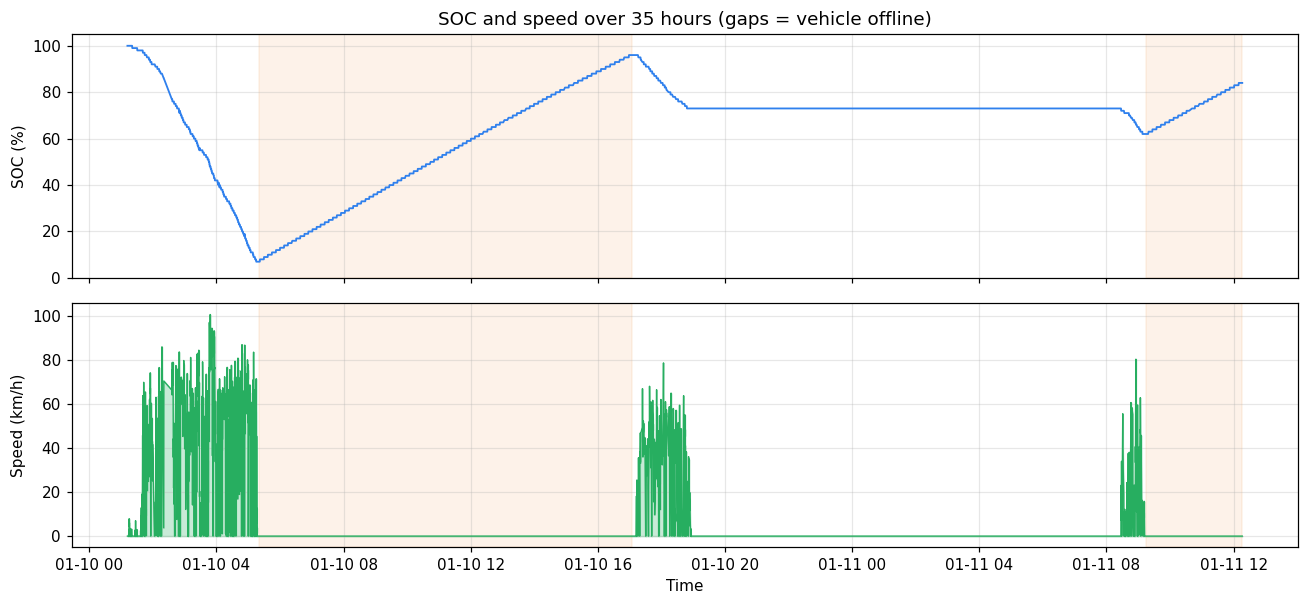

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5.6), sharex=True)
axes[0].plot(df.time, df.soc, color="#2F80ED", lw=1.2)
axes[0].set_ylabel("SOC (%)")
axes[0].set_ylim(0, 105)
axes[0].set_title("SOC and speed over 35 hours (gaps = vehicle offline)")

driving = df.speed > 0
axes[1].plot(df.time, df.speed, color="#27AE60", lw=0.9)
axes[1].fill_between(df.time, 0, df.speed, color="#27AE60", alpha=0.25)
axes[1].set_ylabel("Speed (km/h)")
axes[1].set_xlabel("Time")

# 充电时段标阴影
charging = (df.chargestatus == 1)
grp = (charging != charging.shift()).cumsum()
for _, sub in df[charging].groupby(grp):
    if len(sub) > 30:
        for ax in axes:
            ax.axvspan(sub.time.min(), sub.time.max(), color="#F2994A", alpha=0.12)
fig.tight_layout()
fig.savefig(OUT / "timeline_soc_speed.png", bbox_inches="tight")
plt.show()

**读图**：
- 橙色阴影是停车充电时段——两次充电分别把 SOC 从 7% 拉到 96%、从 62% 拉到 84%。
- 中间那段 SOC 缓慢下降、速度有峰值的，是白天的实际行驶。
- 两次充电都在电量较低时开始（7%、62%），属于「低电量才去补能」的用车习惯。

## 3. 充电行为：2 次慢充，平均 3.25 kW

用 `chargestatus == 1` 的连续段识别充电会话，统计每次的时长、SOC 变化和功率。

In [6]:
group_ids = (df.chargestatus != df.chargestatus.shift()).cumsum()
sessions = []
for gid, sub in df.groupby(group_ids):
    if sub.chargestatus.iloc[0] != 1:
        continue
    minutes = (sub.time.max() - sub.time.min()).total_seconds() / 60
    if minutes < 5:
        continue
    sessions.append({
        "开始": sub.time.min(), "结束": sub.time.max(),
        "时长(分)": round(minutes, 1), "起始SOC": sub.soc.iloc[0], "结束SOC": sub.soc.iloc[-1],
        "SOC增量": sub.soc.iloc[-1] - sub.soc.iloc[0],
        "平均电流(A)": round(sub.sumcurrent.mean(), 2),
        "平均功率(kW)": round(-sub.power_kw.mean(), 2),
        "最高温度(°C)": sub.max_temp.max(),
        "充入电量(kWh)": round(-sub.energy_kwh[sub.dt.between(0, 30)].sum(), 2),
    })
sess = pd.DataFrame(sessions)
print("识别到 %d 次有效充电会话，合计充入 %.2f kWh，平均功率 %.2f kW" % (
    len(sess), sess["充入电量(kWh)"].sum(), sess["平均功率(kW)"].mean()))
sess

识别到 2 次有效充电会话，合计充入 37.58 kWh，平均功率 3.25 kW


,开始,结束,时长(分),起始SOC,结束SOC,SOC增量,平均电流(A),平均功率(kW),最高温度(°C),充入电量(kWh)
0,2019-01-10 05:19:29,2019-01-10 17:04:29,705.0,7,96,89,-9.00,3.25,13,31.81
1,2019-01-11 09:14:48,2019-01-11 12:16:18,181.5,62,84,22,-8.75,3.26,10,5.77


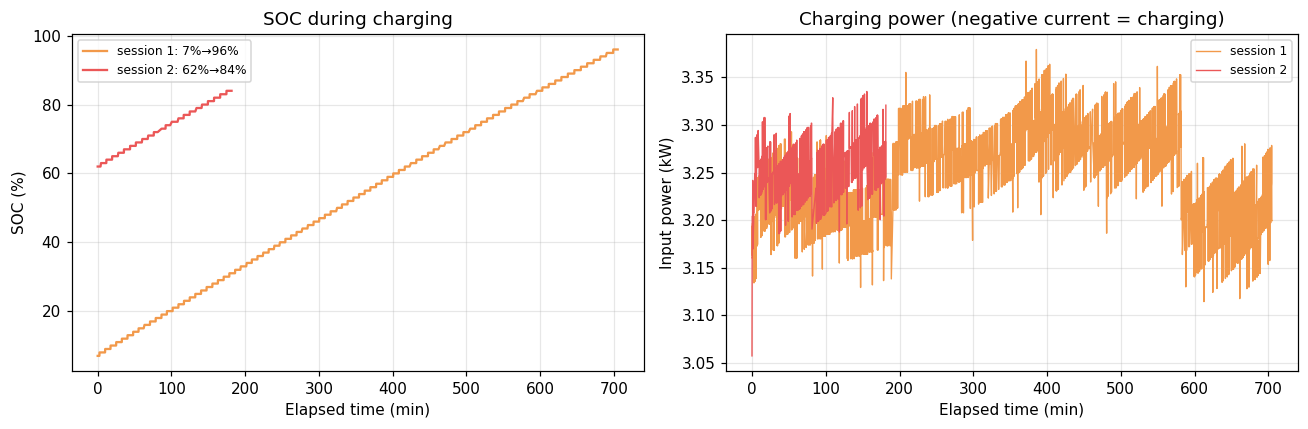

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = ["#F2994A", "#EB5757"]
for i, (_, row) in enumerate(sess.iterrows()):
    sub = df[(df.time >= row["开始"]) & (df.time <= row["结束"])]
    elapsed = (sub.time - sub.time.min()).dt.total_seconds() / 60
    axes[0].plot(elapsed, sub.soc, color=colors[i], label=f"session {i+1}: {row['起始SOC']}%→{row['结束SOC']}%")
    axes[1].plot(elapsed, -sub.power_kw, color=colors[i], lw=0.9, label=f"session {i+1}")

axes[0].set_xlabel("Elapsed time (min)")
axes[0].set_ylabel("SOC (%)")
axes[0].set_title("SOC during charging")
axes[0].legend(fontsize=8)

axes[1].set_xlabel("Elapsed time (min)")
axes[1].set_ylabel("Input power (kW)")
axes[1].set_title("Charging power (negative current = charging)")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "charging_curve.png", bbox_inches="tight")
plt.show()

**结论**：两次都是**交流慢充**（3 kW 级），SOC 曲线接近线性、功率平稳——典型的家用/公司慢充桩场景。如果这是快充，功率曲线会出现"先陡后缓"的恒流恒压特征。

## 4. 电池一致性：电压极差 9 mV 级，最大 96 mV

单体电压极差（最高单体 − 最低单体）是电池一致性最直接的指标：极差越小，电芯越均衡。

In [8]:
print("单体电压极差: 均值 %.4f V, 中位数 %.4f V, p95 %.4f V, 最大 %.4f V" % (
    df.volt_spread.mean(), df.volt_spread.median(),
    df.volt_spread.quantile(.95), df.volt_spread.max()))
print("单体电压范围: %.3f – %.3f V（96 串电池包，额定 ~3.7 V）" % (df.min_cell_volt.min(), df.max_cell_volt.max()))
print("\n不同充电状态下的电压极差（V）:")
print(df.groupby("chargestatus")["volt_spread"].agg(["mean", "max", "count"]).round(4).to_string())
print("\n温度: %.0f – %.0f °C，最大温差 %.0f °C" % (df.min_temp.min(), df.max_temp.max(), df.temp_spread.max()))

单体电压极差: 均值 0.0097 V, 中位数 0.0090 V, p95 0.0170 V, 最大 0.0960 V
单体电压范围: 3.346 – 4.147 V（96 串电池包，额定 ~3.7 V）

不同充电状态下的电压极差（V）:
                mean    max  count
chargestatus                      
1             0.0079  0.015   4366
2             0.0128  0.096    272
3             0.0141  0.076   1539
4             0.0139  0.021     54

温度: 5 – 13 °C，最大温差 2 °C


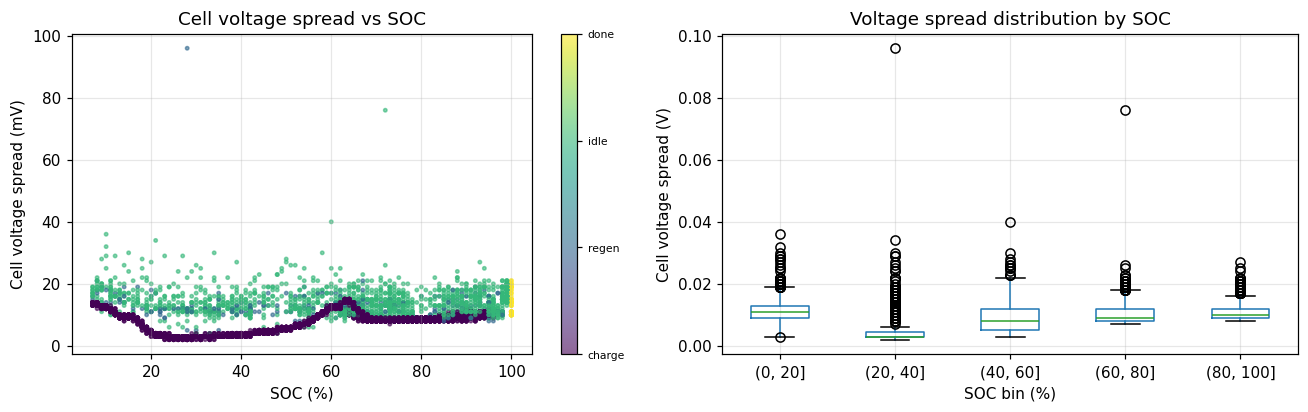

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sc = axes[0].scatter(df.soc, df.volt_spread * 1000, c=df.chargestatus, cmap="viridis", s=5, alpha=0.6)
axes[0].set_xlabel("SOC (%)")
axes[0].set_ylabel("Cell voltage spread (mV)")
axes[0].set_title("Cell voltage spread vs SOC")
cb = fig.colorbar(sc, ax=axes[0], ticks=[1, 2, 3, 4])
cb.ax.set_yticklabels(["charge", "regen", "idle", "done"], fontsize=7)

tmp = df.assign(soc_bin=pd.cut(df.soc, [0, 20, 40, 60, 80, 100]))
tmp.boxplot(column="volt_spread", by="soc_bin", ax=axes[1])
axes[1].set_xlabel("SOC bin (%)")
axes[1].set_ylabel("Cell voltage spread (V)")
axes[1].set_title("Voltage spread distribution by SOC")
fig.suptitle("")
fig.tight_layout()
fig.savefig(OUT / "cell_voltage_consistency.png", bbox_inches="tight")
plt.show()

**结论**：极差中位数 9 mV、p95 为 17 mV，**一致性良好**（96 串电池包中 <20 mV 属于健康水平）；最大 96 mV 只出现在个别瞬间（大概率是低 SOC + 大电流工况下最低单体被拉低）。温度 5–13 °C、温差 ≤2 °C，热管理表现平稳，但需要注意这是**冬季低温**场景，无法代表夏季高温。

## 5. 能耗：21.5 kWh/100km

用 `电压 × 电流 × 时间` 积分得到能量，并且**只对采样间隔 ≤30 秒的段落积分**，避免把 13 小时的缺口当成用电。

In [10]:
valid = df[df.dt.between(0, 30)]
drive = valid[valid.speed > 0]
charge = valid[(valid.sumcurrent < -5) & (valid.speed == 0)]

km = df.mileage.max() - df.mileage.min()
discharge = drive.energy_kwh.clip(lower=0).sum()
charge_in = -charge.energy_kwh.sum()
regen = -valid[(valid.chargestatus == 2)].energy_kwh.sum()

print("累计里程: %.1f → %.1f km，增量 %.1f km" % (df.mileage.min(), df.mileage.max(), km))
print("行驶放电量: %.2f kWh" % discharge)
print("百公里电耗: %.1f kWh/100km" % (discharge / km * 100))
print("充电充入量: %.2f kWh（%d 次慢充）" % (charge_in, len(sess)))
print("行驶中能量回收: %.2f kWh" % max(regen, 0))
print("\n交叉校验：充电充入 %.1f kWh vs 放电 %.1f kWh（加上充电损耗/空调等，同量级说明数据自洽）" % (charge_in, discharge))

累计里程: 39938.0 → 40152.0 km，增量 214.0 km
行驶放电量: 45.96 kWh
百公里电耗: 21.5 kWh/100km
充电充入量: 37.58 kWh（2 次慢充）
行驶中能量回收: 5.72 kWh

交叉校验：充电充入 37.6 kWh vs 放电 46.0 kWh（加上充电损耗/空调等，同量级说明数据自洽）


## 6. 结论与局限

**三条可用的结论：**

1. **用车画像**：35 小时里实际行驶 3.73 小时、214 km，其余时间停车充电或熄火；两次充电都在 SOC 很低时开始（7%、62%），属于"低电量补能"习惯。
2. **充电特性**：两次均为交流慢充，平均功率 3.25 kW、累计充入 37.58 kWh，SOC 曲线线性、功率平稳；起始满电（100%），所以放电量（45.96 kWh）大于本次充入量是合理的。
3. **电池状态**：单体电压极差中位数 9 mV（p95 = 17 mV），温度 5–13 °C、温差 ≤2 °C——一致性良好，冬季热管理平稳。

**局限（面试会被问）：**

- **单辆车、1.5 天**，样本太小，不能代表车队或季节规律；
- 数据覆盖率仅 49.3%，缺 106 段、最长 13.5 小时，**能耗结论依赖积分区间是否完整**；
- `insulationresistance` 的单位口径未确认，本次未用于安全结论；
- 冬季低温环境，无法外推到高温/快充场景（快充需要 60 kW 级功率曲线才看得出恒流恒压特征）。

**下一步**：接入多车数据做车队级对比；把充电会话按桩类型（快充/慢充）分类；用 SOC 变化反推电池可用容量与衰减趋势。